In [1]:
import numpy as np
from scipy.integrate import solve_ivp
from tools import Config
import matplotlib.pyplot as plt
from scipy.optimize import root
from tools_eco import followpars, followpars_with_eqnature, foodweb, foodweb_jacobian_holling_iii
from tools_eco import holling_iii_H, holling_iii_U, simulation_with_pulse

# Initial parameter test

In [28]:
pars_test = Config(dict(muC=2e-2, muH=3e-4, eH=0.5, aH=1e-4, ThH=7, wH = 2, wU = 2,
                        eU=0.5, aU=1e-3, ThU=5, rH=4e-3, K=3000, nu=7e-2, b = 0))
y0 = [500, 1000, 2000]

# Functional response behaviour

In [3]:
import plotly.graph_objects as go

Hgrid, Ugrid = np.meshgrid(np.linspace(0, 3000, 200), np.linspace(0, 5000, 200))
Cfix = 0     # consumer biomass is fixed (it only matters when b > 0)
holling_H_grid = holling_iii_H([Cfix, Hgrid, Ugrid], pars_test)

fig3d = go.Figure(go.Surface(x=Hgrid, y=Ugrid, z=holling_H_grid))
fig3d.update_layout(width=800, height=650,
                    scene=dict(xaxis_title='Herbivore biomass',
                               yaxis_title='Carcass biomass',
                               zaxis_title='Consumption rate of herbivore'))
fig3d.show()

In [4]:
Hgrid, Ugrid = np.meshgrid(np.linspace(0, 3000, 200), np.linspace(0, 5000, 200))
Cfix = 0     # consumer biomass is fixed (it only matters when b > 0)
holling_U_grid = holling_iii_U([Cfix, Hgrid, Ugrid], pars_test)

fig3d = go.Figure(go.Surface(x=Hgrid, y=Ugrid, z=holling_U_grid))
fig3d.update_layout(width=800, height=650,
                    scene=dict(xaxis_title='Herbivore biomass',
                               yaxis_title='Carcass biomass',
                               zaxis_title='Consumption rate on carcasses'))
fig3d.show()

# Population dynamics

In [29]:
Tmax = 8000
tspan = np.linspace(0, Tmax, 10000)
rhs = lambda t, y: foodweb(y, pars_test, holling_iii_H, holling_iii_U)
sol0 = solve_ivp(rhs, [0, Tmax], [500, 1000, 1000], t_eval=tspan)
foo = root(lambda y: foodweb(y, pars_test, holling_iii_H, holling_iii_U), [10, 10, 0])
print(foo.x)
print(foo.success)
sol1 = solve_ivp(rhs, [0, Tmax], [500, 1000, 2000], t_eval=tspan)

Tmax2 = 30
tspan = np.linspace(0, Tmax2, 10000)
sol2 = solve_ivp(rhs, [0, Tmax2], [500, 1000, 5000], t_eval=tspan)

[ 2.16172739 23.57022604  0.        ]
True


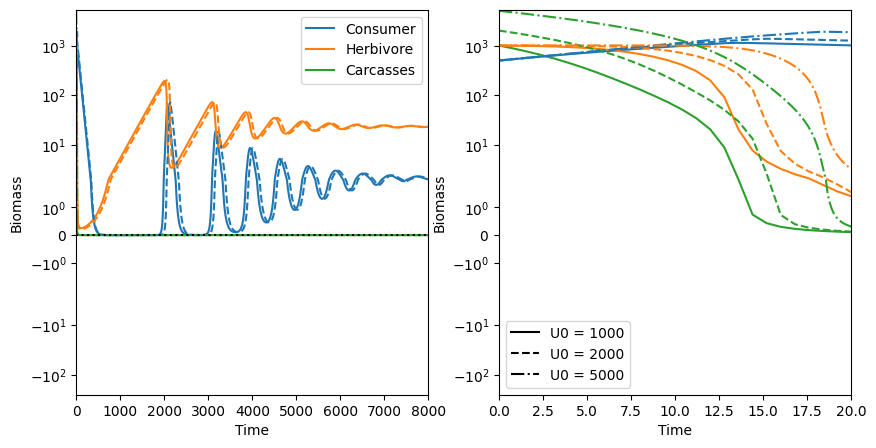

In [30]:
Tend = 20
names = ['Consumer', 'Herbivore', 'Carcasses']
sols  = [sol0, sol1, sol2]
lss   = ['-', '--', '-.']

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))

# first panel: full time
for sol, ls in zip(sols, lss):
    for k in range(3):
        axes[0].plot(sol.t, sol.y[k], linestyle=ls, color=f'C{k}')
for k in range(3):
    axes[0].plot([], [], color=f'C{k}', label=names[k])
axes[0].legend()
axes[0].set_xlim(0, Tmax)
axes[0].set_xlabel('Time')
axes[0].set_ylabel('Biomass')
axes[0].set_yscale('symlog')
axes[0].axhline(1e-12, color = "k", linestyle = 'dotted')

# second panel: zoom on the beginning
for sol, ls in zip(sols, lss):
    for k in range(3):
        axes[1].plot(sol.t, sol.y[k], linestyle=ls, color=f'C{k}')
for sol, ls in zip(sols, lss):
    axes[1].plot([], [], color='k', linestyle=ls, label=f'U0 = {sol.y[2, 0]:g}')
axes[1].legend()
axes[1].set_xlim(0, Tend)
axes[1].set_xlabel('Time')
axes[1].set_ylabel('Biomass')
axes[1].set_yscale('symlog')
plt.show()

# Following growth rate of herbivore

In [7]:
pars = pars_test.clone_me()
y0 = [30, 10, 0]
eq = root(lambda y: foodweb(y, pars, holling_iii_H, holling_iii_U), y0)
print(eq.x)
bp1, e1, n1, c1 = followpars_with_eqnature(foodweb, holling_iii_H, holling_iii_U, 
                                            foodweb_jacobian_holling_iii, 
                                           pars, 'rH', np.linspace(4e-3, 4e-1, 50), eq.x)
bp2, e2, n2, c2 = followpars_with_eqnature(foodweb, holling_iii_H, holling_iii_U, 
                                            foodweb_jacobian_holling_iii, 
                                           pars, 'rH', np.linspace(4e-3, 1e-4, 50), eq.x)
eKlist   = bp2[::-1] + bp1[1:]          
eqK      = np.vstack([e2[::-1], e1[1:]])
eqnatcol = c2[::-1] + c1[1:]
eqnature = n2[::-1] + n1[1:]

[ 2.56018769 17.4077656   0.        ]


In [8]:
idx = [i for i in range(1, len(eqnature)) if eqnature[i] != eqnature[i-1]]
idx

[3, 87]

Text(0.5, 1.0, 'Carcasses')

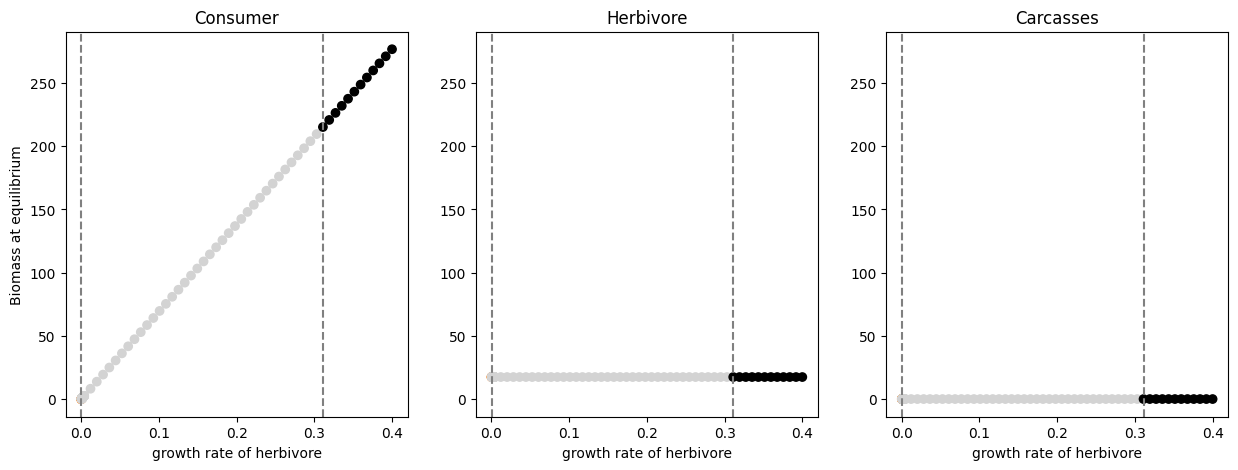

In [9]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5), sharey=True)
for i, ax in enumerate(axes):
    ax.scatter(eKlist, eqK[:, i], color = eqnatcol)
    ax.set_xlabel('growth rate of herbivore')
    ax.tick_params(labelleft=True)
    for k in idx:
        ax.axvline(x=eKlist[k], color='gray', linestyle='dashed')
    #ax.axvline(x = 8e-4, color='red', linestyle='dashed')
axes[0].set_title('Consumer')
axes[0].set_ylabel('Biomass at equilibrium')
axes[1].set_title('Herbivore')
axes[2].set_title('Carcasses')

[ 2.56018769 17.4077656   0.        ]


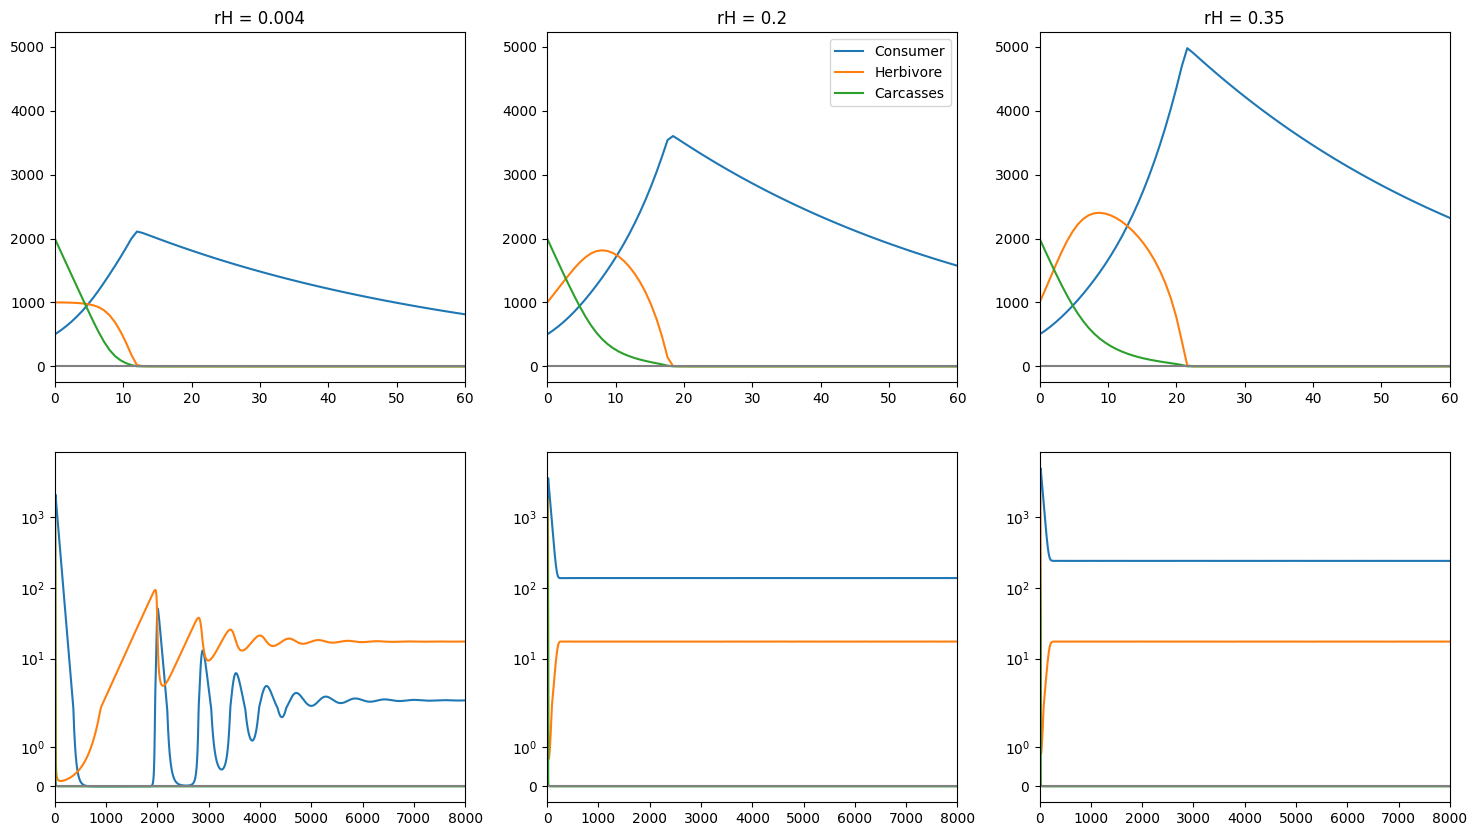

In [10]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10), sharey='row')
parnsol = pars.clone_me()

rhs = lambda t, y: foodweb(y, parnsol, holling_iii_H, holling_iii_U)
y0 = [500, 1000, 2000]
Tmax = 8000
Tend = 60
tspan = np.linspace(0, Tmax, 10000)
labellist = ["Consumer", "Herbivore", "Carcasses"]

nsol = solve_ivp(rhs, [0, Tmax], y0, t_eval=tspan)
foo = root(lambda y: foodweb(y, parnsol, holling_iii_H, holling_iii_U), [80, 10, 0])
print(foo.x)
for i in range(3):
    axes[0, 0].plot(tspan, nsol.y[i])                 
    axes[1, 0].plot(tspan, nsol.y[i])                 
axes[0, 0].set_xlim(0, Tend)
axes[0, 0].set_title(f'rH = {parnsol.rH}')
axes[1, 0].set_xlim(0, Tmax)
axes[0, 0].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[1, 0].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')

parnsol.rH = 0.2
nsol = solve_ivp(rhs, [0, Tmax], y0, t_eval=tspan)
for i in range(3):
    axes[0, 1].plot(tspan, nsol.y[i], label=labellist[i])
    axes[1, 1].plot(tspan, nsol.y[i], label=labellist[i])
axes[0, 1].legend()
axes[0, 1].set_xlim(0, Tend)
axes[0, 1].set_title(f'rH = {parnsol.rH}')
axes[1, 1].set_xlim(0, Tmax)
axes[0, 1].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[1, 1].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')

parnsol.rH = 0.35
nsol = solve_ivp(rhs, [0, Tmax], y0, t_eval=tspan)
for i in range(3):
    axes[0, 2].plot(tspan, nsol.y[i])
    axes[1, 2].plot(tspan, nsol.y[i])
axes[0, 2].set_xlim(0, Tend)
axes[0, 2].set_title(f'rH = {parnsol.rH}')
axes[1, 2].set_xlim(0, Tmax)
axes[0, 2].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')
axes[1, 2].hlines(y=0, xmin=tspan[0], xmax=tspan[-1], color='gray')

for ax in axes.flat:
    ax.tick_params(labelleft=True)
for ax in axes[1, :]:
    ax.set_yscale('symlog')

# Following handling time for carcasses ThU

In [11]:
pars = pars_test.clone_me()
y0 = [80, 300, 0]
eq = root(lambda y: foodweb(y, pars, holling_iii_H, holling_iii_U), y0)
bp1, e1, n1, c1 = followpars_with_eqnature(foodweb, holling_iii_H, holling_iii_U,
                                           foodweb_jacobian_holling_iii, pars, 'ThU', 
                                          np.linspace(5, 10, 50), eq.x)
bp2, e2, n2, c2 = followpars_with_eqnature(foodweb, holling_iii_H, holling_iii_U,
                                           foodweb_jacobian_holling_iii, pars, 'ThU', 
                                          np.linspace(5, 3, 50), eq.x)
eThUlist   = bp2[::-1] + bp1[1::] 
eqThU     = np.vstack([e2[::-1], e1[1:]])
eqnatcol = c2[::-1] + c1[1:]
eqnature = n2[::-1] + n1[1:]

/var/folders/_d/7z_bnz2j4w59tl82v3jb7qxc0000gn/T/ipykernel_43664/3945424151.py:6: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(ymin, ymax)


Text(0, 0.5, 'Biomass at equilibrium')

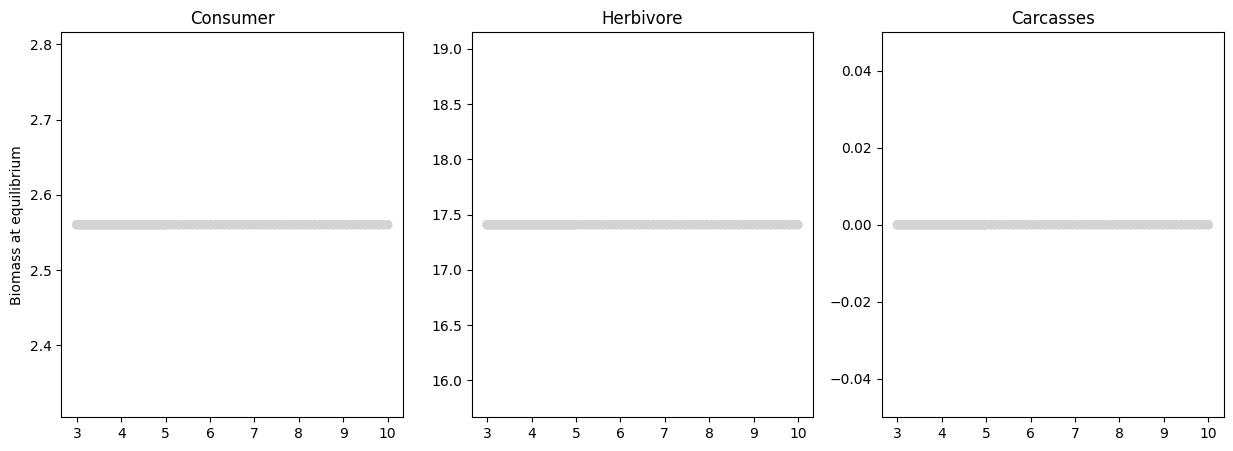

In [12]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
for i, ax in enumerate(axes):
    ax.scatter(eThUlist, eqThU[:, i], color = eqnatcol)
    ymin = min(eqThU[:, i]) - min(eqThU[:, i])/10
    ymax = max(eqThU[:, i]) + max(eqThU[:, i])/10
    ax.set_ylim(ymin, ymax)
axes[0].set_title('Consumer')
axes[1].set_title('Herbivore')
axes[2].set_title('Carcasses')
axes[0].set_ylabel('Biomass at equilibrium')

# Follow handling time for herbivore ThH

In [13]:
pars = pars_test.clone_me()
y0 = [80, 300, 0]
eq = root(lambda y: foodweb(y, pars, holling_iii_H, holling_iii_U), y0)
print(eq.x)
bp1, e1, n1, c1 = followpars_with_eqnature(foodweb, holling_iii_H, holling_iii_U, 
                                            foodweb_jacobian_holling_iii, 
                                           pars, 'ThH', np.linspace(7, 10.5, 50), eq.x)
bp2, e2, n2, c2 = followpars_with_eqnature(foodweb, holling_iii_H, holling_iii_U, 
                                            foodweb_jacobian_holling_iii, 
                                          pars, 'ThH', np.linspace(7, 3, 50), eq.x)
eThHlist   = bp2[::-1] + bp1[1::] 
eqThH     = np.vstack([e2[::-1], e1[1:]])
eqnatcol = c2[::-1] + c1[1:]
eqnature = n2[::-1] + n1[1:]

[ 2.56018769 17.4077656   0.        ]


/var/folders/_d/7z_bnz2j4w59tl82v3jb7qxc0000gn/T/ipykernel_43664/4263879498.py:6: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(ymin, ymax)


Text(0.5, 1.0, 'Carcasses')

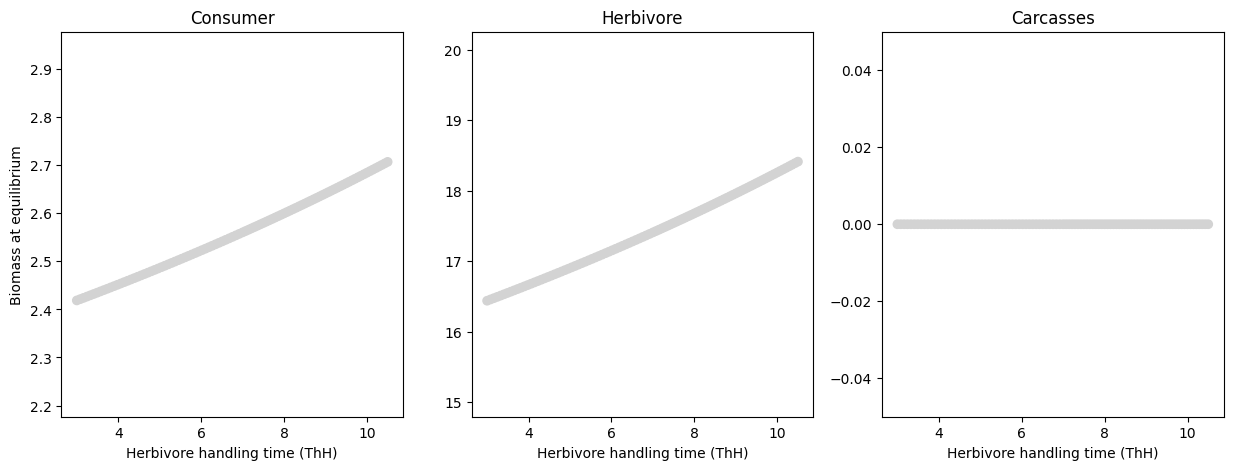

In [14]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
for i, ax in enumerate(axes):
    ax.scatter(eThHlist, eqThH[:, i], color = eqnatcol)
    ymin = min(eqThH[:, i]) - min(eqThH[:, i])/10
    ymax = max(eqThH[:, i]) + max(eqThH[:, i])/10
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel('Herbivore handling time (ThH)')
axes[0].set_title('Consumer')
axes[0].set_ylabel('Biomass at equilibrium')
axes[1].set_title('Herbivore')
axes[2].set_title('Carcasses')

# Following muH

In [16]:
pars = pars_test.clone_me()
y0 = [10, 30, 0]
eq = root(lambda y: foodweb(y, pars, holling_iii_H, holling_iii_U), y0)
print(eq.x)
emuH, eqmuH, eqnature, eqnatcol = followpars_with_eqnature(foodweb, holling_iii_H, holling_iii_U, 
                                                           foodweb_jacobian_holling_iii, pars, 'muH', 
                                                            np.linspace(3e-4, 3e-3, 50), eq.x)

[ 2.56018769 17.4077656   0.        ]


/var/folders/_d/7z_bnz2j4w59tl82v3jb7qxc0000gn/T/ipykernel_43664/2760123173.py:6: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(ymin, ymax)


Text(0.5, 1.0, 'Carcasses')

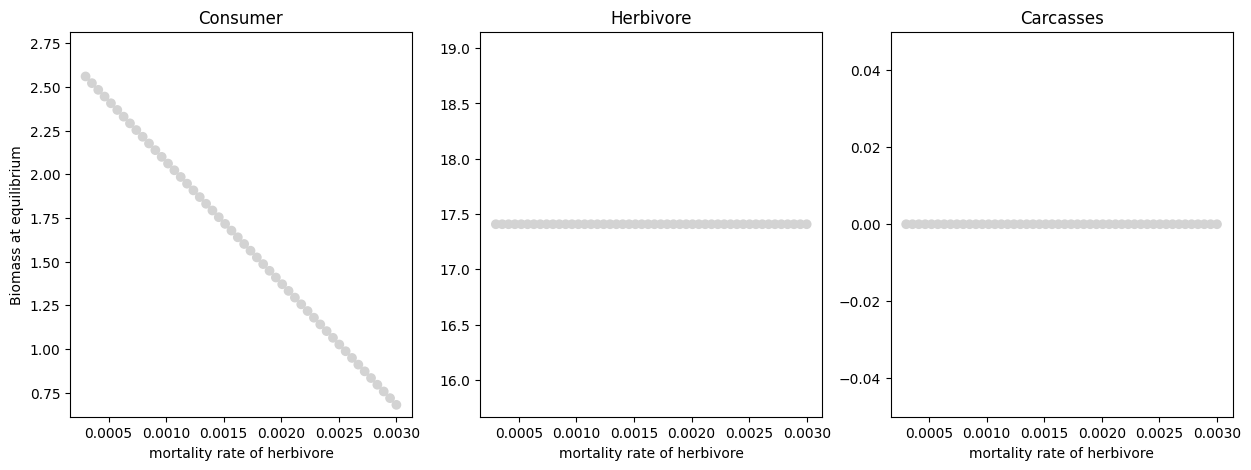

In [17]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
for i, ax in enumerate(axes):
    ax.scatter(emuH, eqmuH[:, i], color = eqnatcol)
    ymin = min(eqmuH[:, i]) - min(eqmuH[:, i])/10
    ymax = max(eqmuH[:, i]) + max(eqmuH[:, i])/10
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel('mortality rate of herbivore')
axes[0].set_title('Consumer')
axes[0].hlines(y=0, xmin=emuH[0], xmax=emuH[-1], color='gray')
axes[0].set_ylabel('Biomass at equilibrium')
axes[1].set_title('Herbivore')
axes[2].set_title('Carcasses')

# Follow attack rate on carcasses

In [19]:
pars = pars_test.clone_me()

y0 = [30, 30, 0]
eq = root(lambda y: foodweb(y, pars, holling_iii_H, holling_iii_U), y0)
print(eq.x)
bp1, e1, n1, c1 = followpars_with_eqnature(foodweb, holling_iii_H, holling_iii_U, 
                                            foodweb_jacobian_holling_iii, 
                                           pars, 'aU', np.linspace(1e-3, 3e-3, 50), eq.x)
bp2, e2, n2, c2 = followpars_with_eqnature(foodweb, holling_iii_H, holling_iii_U, 
                                            foodweb_jacobian_holling_iii, 
                                           pars, 'aU', np.linspace(1e-3, 5e-5, 50), eq.x)
eaU   = bp2[::-1] + bp1[1::] 
eqaU     = np.vstack([e2[::-1], e1[1:]])
eqnatcol = c2[::-1] + c1[1:]
eqnature = n2[::-1] + n1[1:]

[ 2.56018769 17.4077656   0.        ]


/var/folders/_d/7z_bnz2j4w59tl82v3jb7qxc0000gn/T/ipykernel_43664/1662308948.py:6: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(ymin, ymax)


Text(0.5, 1.0, 'Carcasses')

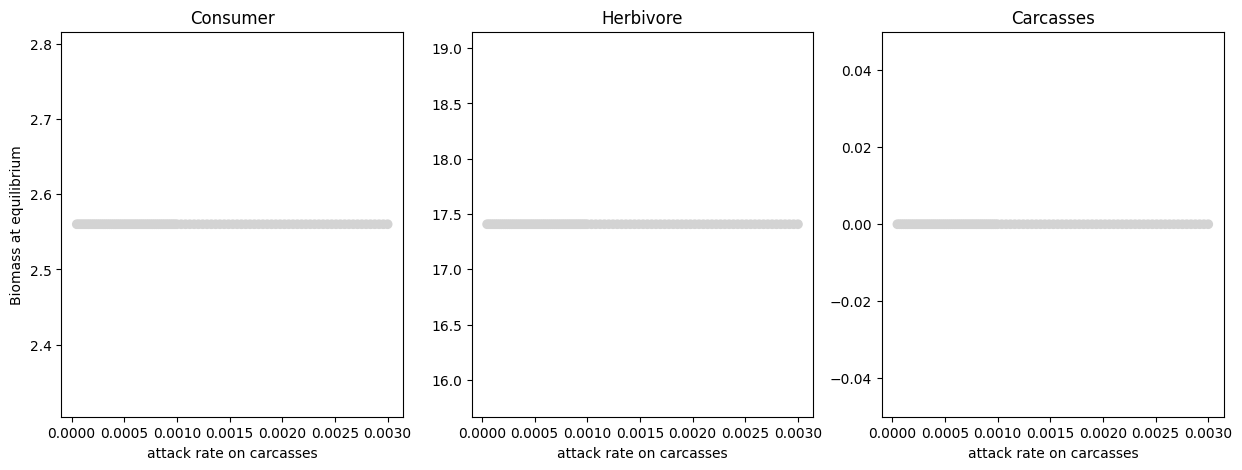

In [20]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))
for i, ax in enumerate(axes):
    ax.scatter(eaU, eqaU[:, i], color = eqnatcol)
    ymin = min(eqaU[:, i]) - min(eqaU[:, i])/10
    ymax = max(eqaU[:, i]) + max(eqaU[:, i])/10
    ax.set_ylim(ymin, ymax)
    ax.set_xlabel('attack rate on carcasses')
axes[0].set_title('Consumer')
axes[0].hlines(y=0, xmin=eaU[0], xmax=eaU[-1], color='gray')
axes[0].set_ylabel('Biomass at equilibrium')
axes[1].set_title('Herbivore')
axes[2].set_title('Carcasses')